In [1]:
import pandas as pd
import sklearn
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import sklearn
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

### Data Preparation

In [2]:
df = pd.read_csv(r'C:\Users\Виталий\PycharmProjects\MLZoomcamp2026\course_lead_scoring_2026.csv')

In [3]:
df.isna().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [4]:
cat_cols = ['lead_source', 'industry', 'employment_status', 'location']
num_cols = ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score', 'converted']

df[cat_cols] = df[cat_cols].fillna("NA")
df[num_cols] = df[num_cols].fillna(0.0)
df.isna().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

## Question 1

In [5]:
df.industry.value_counts()

industry
technology       1173
retail            925
healthcare        840
finance           720
education         639
manufacturing     463
NA                240
Name: count, dtype: int64

## Question 2

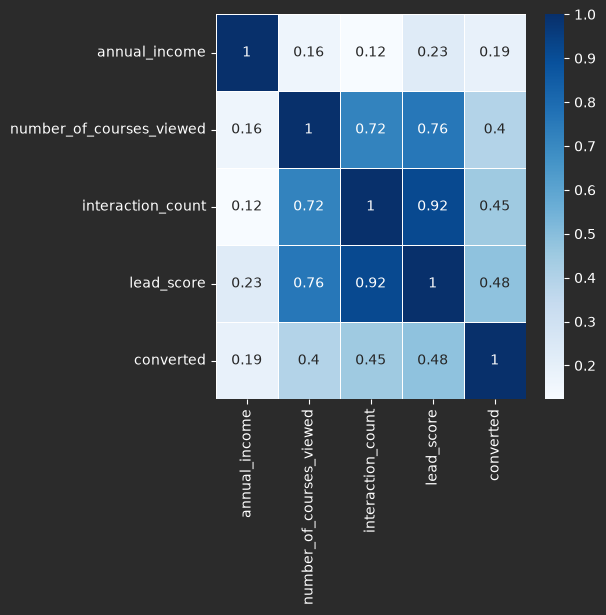

In [6]:
df_num_col_copy = df[num_cols].copy()
plt.figure(figsize=(5,5))
sns.heatmap(df_num_col_copy.corr(), annot=True, linewidths=.5, cmap=plt.cm.Blues)
plt.show()

### Split dataset

In [7]:
df_full_train, df_test = train_test_split(df, test_size = 0.2, random_state = 42)
df_train, df_val = train_test_split(df_full_train, test_size = 0.25, random_state = 42)

In [8]:
df_train.reset_index(drop = True)
df_val.reset_index(drop = True)
df_test.reset_index(drop = True)

y_train = df_train.converted.values
y_val = df_val.converted.values
y_test = df_test.converted.values

del df_train['converted']
del df_val['converted']
del df_test['converted']

## Question 3

In [9]:
from sklearn.metrics import mutual_info_score, accuracy_score


def mutual_info_churn_score(series):
    return round(mutual_info_score(series, y_train), 3)

In [10]:
mi = df_train[cat_cols].apply(mutual_info_churn_score)
mi.sort_values(ascending = False)

lead_source          0.034
employment_status    0.019
industry             0.002
location             0.001
dtype: float64

### One-hot encording

In [11]:
from sklearn.feature_extraction import DictVectorizer

dv = DictVectorizer(sparse=False)

In [12]:
train_dict = df_train.to_dict(orient='records')
X_train = dv.fit_transform(train_dict)

val_dict = df_val.to_dict(orient='records')
X_val = dv.transform(val_dict)

### Training model

In [13]:
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_val)

accuracy = np.round(accuracy_score(y_val, y_pred), 3)
print(accuracy)

0.645


## Question 5

In [14]:
features = cat_cols + num_cols[:-1]
features

['lead_source',
 'industry',
 'employment_status',
 'location',
 'annual_income',
 'number_of_courses_viewed',
 'interaction_count',
 'lead_score']

In [15]:
for feature in features:
    sub_features = features.copy()
    sub_features.remove(feature)

    train_dict = df_train[sub_features].to_dict(orient='records')
    dv = DictVectorizer(sparse=False)

    X_train = dv.fit_transform(train_dict)

    model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)
    model.fit(X_train, y_train)

    val_dict = df_val[sub_features].to_dict(orient='records')
    X_val = dv.transform(val_dict)
    y_pred = model.predict(X_val)

    accuracy_without_feature = accuracy_score(y_val, y_pred)
    print(f"{feature:^24}", abs(accuracy - accuracy_without_feature))

      lead_source        0.0030000000000000027
        industry         0.0
   employment_status     0.0
        location         0.0
     annual_income       0.07899999999999996
number_of_courses_viewed 0.0020000000000000018
   interaction_count     0.04400000000000004
       lead_score        0.0010000000000000009


## Question 6

### Data split and one-hot encording

In [16]:
dv = DictVectorizer(sparse=False)

train_dict = df_train.to_dict(orient='records')
X_train = dv.fit_transform(train_dict)

val_dict = df_val.to_dict(orient='records')
X_val = dv.transform(val_dict)

### Training models with different paraneter C

In [17]:
C_list = [0.000001, 0.00001, 0.0001, 0.001]

for C in C_list:
    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000, random_state=42)
    model.fit(X_train, y_train)

    y_pred = model.predict(X_val)
    accuracy = np.round(accuracy_score(y_val, y_pred), 3)
    print(f"{C:^8}", abs(accuracy))

 1e-06   0.598
 1e-05   0.598
 0.0001  0.613
 0.001   0.645
